# Event return distributions by pre-event trend

Compare **Downtrend, Flat, and Uptrend**, using the existing **+/-0.02** flat band from `rolling_brier.ipynb`'s original trend definition. No threshold search or significance tests are performed here.

Returns are event profit (moneylines **plus parlays**) divided by bankroll before the event, in percent. Each event receives equal weight. The main plots pool validation and test; separate split plots follow.

Trend uses Vegas-minus-model Brier advantage averaged over 100 fights, sampled at event end, smoothed with a 5-event EWMA, then a slope over 5 smoothed points. Slope is normalized by the fitted model's smoothed-series standard deviation over the original training calendar period. All trend inputs end before the return event. The matching model and history are used for each split. Training histories include fitted probabilities; these are descriptive distributions, not prospective validation of the filter.


In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / 'src' / 'ufc_betting').is_dir()), None)
if ROOT is None:
    raise RuntimeError('Run from inside the SportsBetting repository')
if str(ROOT / 'src') not in sys.path:
    sys.path.insert(0, str(ROOT / 'src'))
from ufc_betting.config import settings


In [2]:
# Self-contained analysis: no dependence on later notebook cells.
from scipy.stats import pearsonr, spearmanr
MEAN_ADV_WINDOW = 100
mean_adv_root = settings.data_dir / 'model_comparisons/lr_open_close/report_predictions'
mean_adv_backtests = settings.data_dir / 'backtest_results/model_comparisons/inference_market_models'
mean_adv_keys = ['date','fighter_red','fighter_blue']

def mean_adv_score(frame):
    frame = frame.copy()
    frame['date'] = pd.to_datetime(frame.date).dt.normalize()
    model = pd.to_numeric(frame.proba_red,errors='coerce')
    red = pd.to_numeric(frame.dec_open_red,errors='coerce')
    blue = pd.to_numeric(frame.dec_open_blue,errors='coerce')
    good = frame.winner.isin([0,1]) & model.between(0,1) & np.isfinite(red) & np.isfinite(blue) & red.gt(1) & blue.gt(1)
    vegas = (1/red)/(1/red+1/blue)
    frame = frame.loc[good].copy()
    frame['advantage'] = ((vegas-frame.winner)**2-(model-frame.winner)**2).loc[good]
    frame['model_correct'] = (model.loc[good].ge(.5).astype(int)==frame.winner).astype(int)
    frame['vegas_correct'] = (vegas.loc[good].ge(.5).astype(int)==frame.winner).astype(int)
    return frame.sort_values('date',kind='stable').reset_index(drop=True)

mean_adv_train = mean_adv_score(pd.read_csv(mean_adv_root/'train/open/inference/train_with_open.csv'))
mean_adv_train['rolling_advantage'] = mean_adv_train.advantage.rolling(MEAN_ADV_WINDOW,min_periods=MEAN_ADV_WINDOW).mean()
mean_adv_training_mean = mean_adv_train.rolling_advantage.mean()
mean_adv_training_end = mean_adv_train.date.max()
mean_adv_train_endpoints = mean_adv_train.groupby('date').rolling_advantage.last()
mean_adv_train['prior_event_advantage'] = mean_adv_train.date.map(mean_adv_train_endpoints.shift(1))
mean_adv_return_pairs={};mean_adv_corr_rows=[];mean_adv_histories={}
for split,fit,prefix,prediction_split in [('Validation','train','train_val','val'),('Test','trainval','trainval_test','test')]:
    base=mean_adv_root/fit/'open/inference'
    warm=mean_adv_score(pd.read_csv(base/'train_with_open.csv'))
    prediction=pd.read_csv(base/f'{prediction_split}_with_open.csv',parse_dates=['date'])
    saved=pd.read_csv(mean_adv_backtests/f'{prefix}_open_with_open_inference_no_decay_moneylines.csv',parse_dates=['date'])
    for frame in [prediction,saved]:frame['date']=frame.date.dt.normalize()
    matched=saved.merge(prediction[mean_adv_keys+['proba_red','dec_open_red','dec_open_blue']],
        on=mean_adv_keys,how='outer',validate='one_to_one',indicator=True,suffixes=('','_reference'))
    assert matched['_merge'].eq('both').all()
    reference_model=matched['proba_red_reference'] if 'proba_red_reference' in matched else matched.proba_red
    np.testing.assert_allclose(matched.choice_proba.where(matched.pred_winner.eq(1),1-matched.choice_proba),reference_model,atol=1e-10)
    # Preserve saved within-event order exactly as in preceding correlation analyses.
    ordered=saved[mean_adv_keys].merge(prediction,on=mean_adv_keys,validate='one_to_one',sort=False)
    current=mean_adv_score(ordered)
    assert warm.date.max()<current.date.min()
    history=pd.concat([warm,current],ignore_index=True).sort_values('date',kind='stable').reset_index(drop=True)
    history['rolling_advantage']=history.advantage.rolling(MEAN_ADV_WINDOW,min_periods=MEAN_ADV_WINDOW).mean()
    # Same original training calendar period for both baselines, using each strategy's matching model.
    reference_mean=history.loc[history.date<=mean_adv_training_end,'rolling_advantage'].mean()
    if split=='Validation':np.testing.assert_allclose(reference_mean,mean_adv_training_mean,atol=1e-12)
    endpoints=history.groupby('date').rolling_advantage.last()
    cols=['bankroll_postevent','event_payout_money_line','parlay_net']
    assert saved.groupby('date')[cols].nunique(dropna=False).le(1).all().all()
    event=saved.groupby('date')[cols].first().sort_index()
    profit=event.event_payout_money_line+event.parlay_net
    start=event.bankroll_postevent-profit
    assert start.gt(0).all()
    np.testing.assert_allclose(start.iloc[1:],event.bankroll_postevent.iloc[:-1],rtol=1e-8,atol=1e-8)
    pair=pd.DataFrame({'prior_advantage':endpoints.shift(1),'feature_date':pd.Series(endpoints.index,index=endpoints.index).shift(1)})
    pair=pair.reindex(event.index)
    pair['return_pct']=100*profit/start
    pair['signed_distance']=pair.prior_advantage-reference_mean
    pair['absolute_distance']=pair.signed_distance.abs()
    assert pair.notna().all().all() and (pair.feature_date<pair.index).all()
    mean_adv_return_pairs[split]=pair;mean_adv_histories[split]=history


In [3]:
# Smoothed direction AND level; all features stop before the target event.
TREND_EWMA_SPAN=5
TREND_SLOPE_EVENTS=5
FLAT_SLOPE_SD_PER_EVENT = 0.02  # Original trend definition.
trend_parts=[]
for split,pair in mean_adv_return_pairs.items():
    endpoint=mean_adv_histories[split].groupby('date').rolling_advantage.last().dropna()
    smooth=endpoint.ewm(span=TREND_EWMA_SPAN,adjust=False).mean()
    t=np.arange(TREND_SLOPE_EVENTS,dtype=float);t-=t.mean()
    slope=smooth.rolling(TREND_SLOPE_EVENTS).apply(lambda x:np.dot(t,x)/np.dot(t,t),raw=True)
    historical_sd=smooth.loc[smooth.index<=mean_adv_training_end].std(ddof=1)
    assert historical_sd>0
    features=pd.DataFrame({'smoothed_advantage':smooth,'slope':slope,'slope_sd_per_event':slope/historical_sd})
    features['source_date']=features.index
    features=features.shift(1).reindex(pair.index)
    assert (features.source_date<features.index).all()
    features['return_pct']=pair.return_pct
    features['split']=split
    features['trend']=np.select([features.slope_sd_per_event>FLAT_SLOPE_SD_PER_EVENT,
        features.slope_sd_per_event < -FLAT_SLOPE_SD_PER_EVENT],['Uptrend','Downtrend'],default='Flat')
    trend_parts.append(features)
regime_trend_data=pd.concat(trend_parts).sort_index()
assert regime_trend_data.notna().all().all()
trend_returns = regime_trend_data.copy()
assert trend_returns.index.is_unique
assert np.isfinite(trend_returns.return_pct).all()
assert trend_returns.return_pct.gt(-100).all()
TREND_ORDER = ['Downtrend', 'Flat', 'Uptrend']
COLORS = {'Downtrend': 'tab:red', 'Flat': 'tab:blue', 'Uptrend': 'tab:green'}
print(f'Flat: normalized slope between {-FLAT_SLOPE_SD_PER_EVENT:.2f} and +{FLAT_SLOPE_SD_PER_EVENT:.2f}, inclusive')
print(pd.crosstab(trend_returns['split'], trend_returns.trend).reindex(columns=TREND_ORDER).to_string())


Flat: normalized slope between -0.02 and +0.02, inclusive
trend       Downtrend  Flat  Uptrend
split                               
Test               12     4       17
Validation         38     9       25


## Distribution summary

Percentiles describe observed returns, not confidence intervals. Standard deviation is in percentage points. Negative-event frequency counts returns strictly below zero. Geometric return describes compounding per event within each group.


In [4]:
summary_rows = []
for split, sample in [('Combined', trend_returns), *list(trend_returns.groupby('split', sort=False))]:
    for trend in TREND_ORDER:
        r = sample.loc[sample.trend.eq(trend), 'return_pct']
        summary_rows.append(dict(split=split, trend=trend, events=len(r),
            mean_pct=r.mean(), median_pct=r.median(), std_pp=r.std(ddof=1),
            min_pct=r.min(), p10_pct=r.quantile(.1), p25_pct=r.quantile(.25),
            p75_pct=r.quantile(.75), p90_pct=r.quantile(.9), max_pct=r.max(),
            negative_events_pct=100*r.lt(0).mean(),
            geometric_return_pct=100*np.expm1(np.log1p(r/100).mean())))
return_summary = pd.DataFrame(summary_rows).set_index(['split', 'trend'])
print(return_summary.round(3).to_string())


                      events  mean_pct  median_pct  std_pp  min_pct  p10_pct  p25_pct  p75_pct  p90_pct  max_pct  negative_events_pct  geometric_return_pct
split      trend                                                                                                                                           
Combined   Downtrend      50    18.663      22.917  35.273  -74.315  -22.137   -7.661   39.341   58.822  110.608               30.000                12.645
           Flat           13   -15.035     -20.282  37.174  -62.496  -56.647  -48.275   17.001   26.614   43.402               53.846               -22.903
           Uptrend        42    18.418      21.288  29.112  -50.513  -21.803    1.861   38.834   50.244   68.030               21.429                14.317
Validation Downtrend      38    20.779      28.171  34.207  -38.118  -22.341   -0.675   39.341   58.833  110.608               26.316                15.998
           Flat            9    -7.181       0.713  38.487  -57.

## Pooled return distributions

Histograms use identical bin edges and normalize each trend to 100%, so unequal group sizes do not dominate. The empirical cumulative distribution shows the fraction of events at or below each return. Box plots show the median and interquartile range, with whiskers extending to observations within 1.5 IQR; dots show every event.


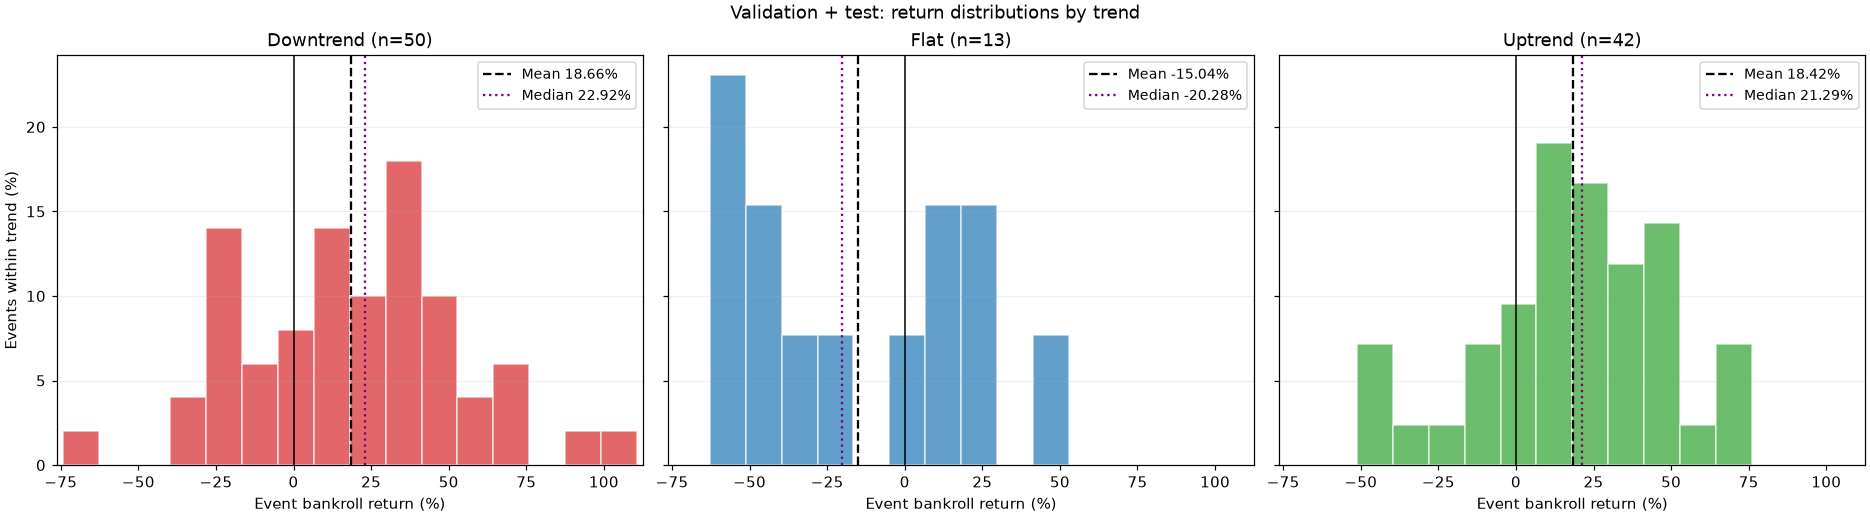

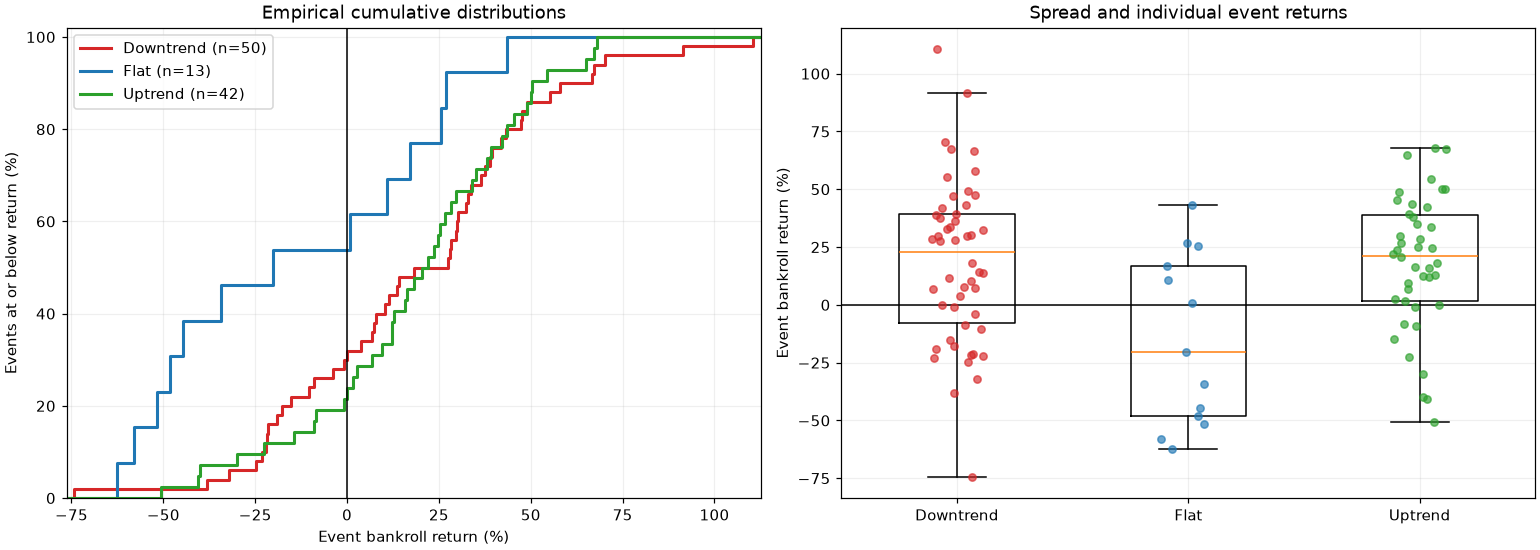

In [5]:
bins = np.histogram_bin_edges(trend_returns.return_pct, bins=16)
x_limits = (min(bins[0], 0)-2, max(bins[-1], 0)+2)
fig, axes = plt.subplots(1, 3, figsize=(17, 4.7), sharex=True, sharey=True, constrained_layout=True)
for ax, trend in zip(axes, TREND_ORDER):
    r = trend_returns.loc[trend_returns.trend.eq(trend), 'return_pct']
    ax.hist(r, bins=bins, weights=np.full(len(r), 100/len(r)), color=COLORS[trend], alpha=.7, edgecolor='white')
    ax.axvline(0, color='black', lw=1)
    ax.axvline(r.mean(), color='black', ls='--', label=f'Mean {r.mean():.2f}%')
    ax.axvline(r.median(), color='purple', ls=':', label=f'Median {r.median():.2f}%')
    ax.set(title=f'{trend} (n={len(r)})', xlabel='Event bankroll return (%)', xlim=x_limits)
    ax.legend(fontsize=9); ax.grid(axis='y', alpha=.2)
axes[0].set_ylabel('Events within trend (%)')
fig.suptitle('Validation + test: return distributions by trend')
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(14, 5), constrained_layout=True)
rng = np.random.default_rng(42)
values = []
for i, trend in enumerate(TREND_ORDER, 1):
    r = np.sort(trend_returns.loc[trend_returns.trend.eq(trend), 'return_pct'].to_numpy())
    values.append(r)
    axes[0].step(np.r_[x_limits[0], r, x_limits[1]], np.r_[0, np.arange(1, len(r)+1)/len(r)*100, 100],
                 where='post', color=COLORS[trend], label=f'{trend} (n={len(r)})', lw=2)
    axes[1].scatter(i+rng.uniform(-.12, .12, len(r)), r, color=COLORS[trend], alpha=.65, s=23, zorder=3)
axes[0].axvline(0, color='black', lw=1)
axes[0].set(title='Empirical cumulative distributions', xlabel='Event bankroll return (%)',
            ylabel='Events at or below return (%)', xlim=x_limits, ylim=(0, 102))
axes[0].legend()
axes[1].boxplot(values, tick_labels=TREND_ORDER, showfliers=False, widths=.5)
axes[1].axhline(0, color='black', lw=1)
axes[1].set(title='Spread and individual event returns', ylabel='Event bankroll return (%)')
for ax in axes: ax.grid(alpha=.2)
plt.show()


## Validation and test separately

The test strategy uses a model refitted on training plus validation. These panels expose differences between the two periods, using the same bins and axes as the pooled histograms.


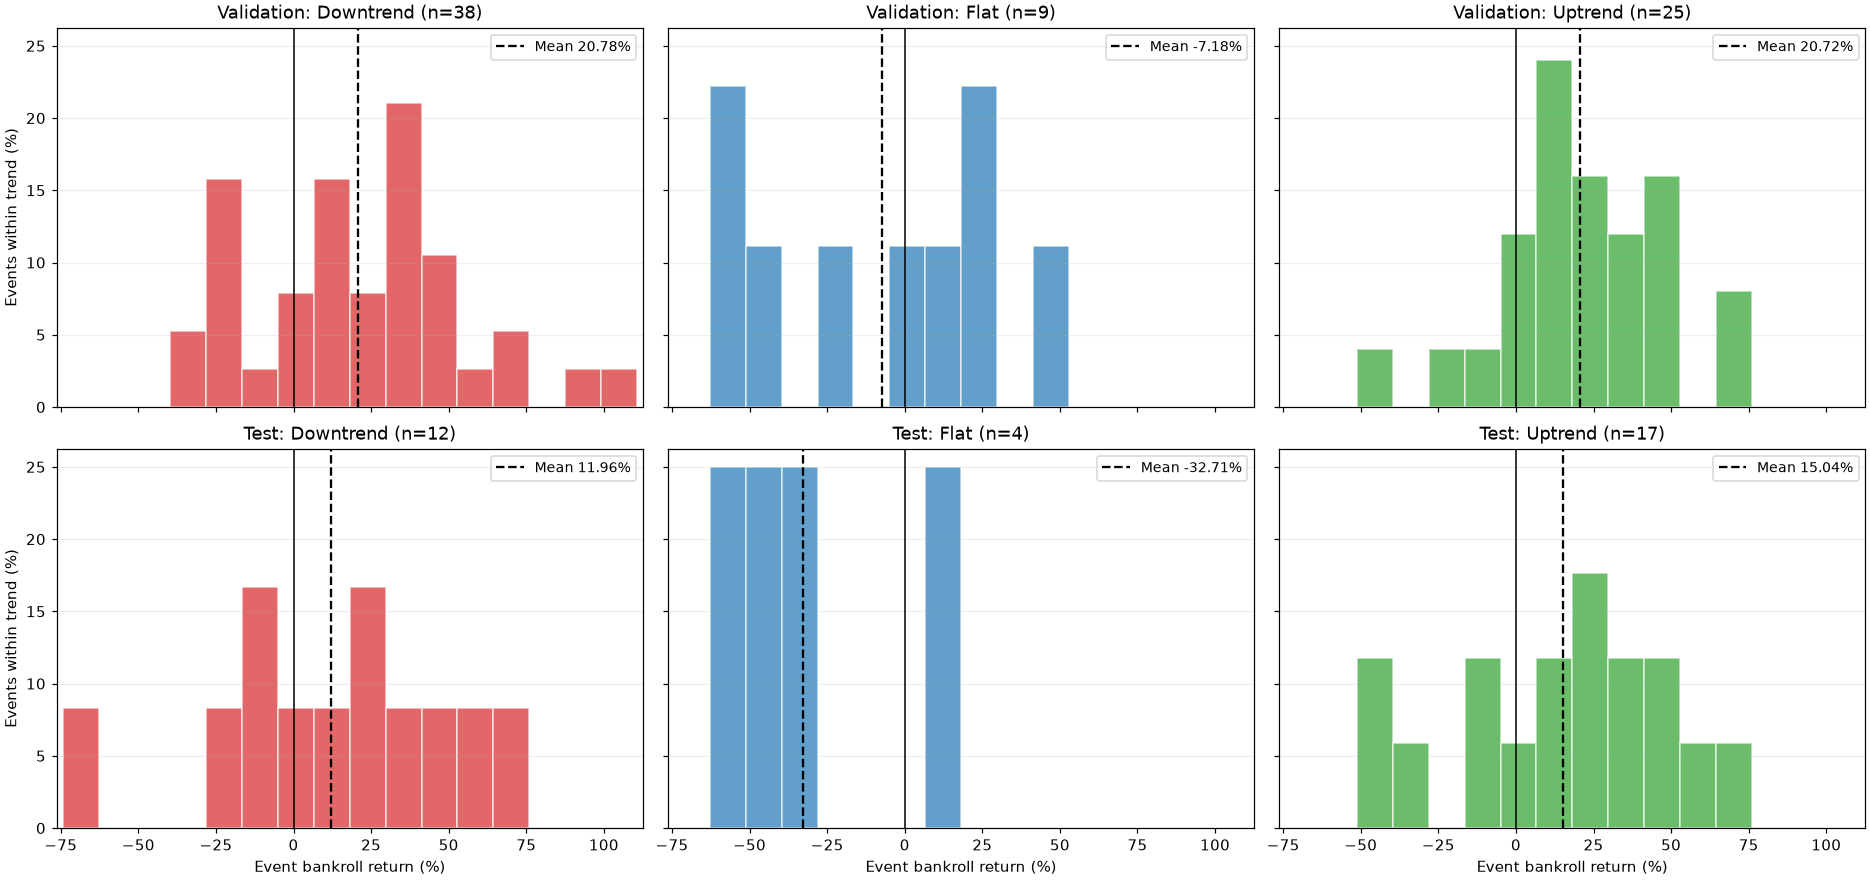

In [6]:
fig, axes = plt.subplots(2, 3, figsize=(17, 8), sharex=True, sharey=True, constrained_layout=True)
for row, split in enumerate(['Validation', 'Test']):
    for col, trend in enumerate(TREND_ORDER):
        ax = axes[row, col]
        r = trend_returns.loc[trend_returns.split.eq(split) & trend_returns.trend.eq(trend), 'return_pct']
        if len(r):
            ax.hist(r, bins=bins, weights=np.full(len(r), 100/len(r)), color=COLORS[trend], alpha=.7, edgecolor='white')
            ax.axvline(r.mean(), color='black', ls='--', label=f'Mean {r.mean():.2f}%')
            ax.legend(fontsize=9)
        ax.axvline(0, color='black', lw=1)
        ax.set(title=f'{split}: {trend} (n={len(r)})', xlim=x_limits)
        ax.grid(axis='y', alpha=.2)
        if row == 1: ax.set_xlabel('Event bankroll return (%)')
        if col == 0: ax.set_ylabel('Events within trend (%)')
plt.show()
